# Employee Attrition Flight-Risk Prediction — Machine Learning Project
**Team:** Gabriel Jaycee Near, Geitth Andrew Lamasan, John Vincent Wilson, Paul Brian Ticar  
**Date:** November 19, 2026 (Checkpoint: Stages B, C, and D)  

**Summary:** Using 1,470 employee records and demographic, commute, and travel attributes, we frame employee attrition (`Attrition`: `Yes` vs. `No`) as an imbalanced binary classification task (~16.1% attrition) to help HR prioritize targeted retention outreach. All preprocessing steps are encapsulated inside scikit-learn `Pipeline`s and evaluated via 5-fold stratified cross-validation on the training set against a naive baseline, while the 25% test set remains untouched until Stage E.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import sys
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    f1_score,
)

SEED = 77
random.seed(SEED)
np.random.seed(SEED)

print(f"Random Seed: {SEED}")
print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__} | numpy: {np.__version__} | scikit-learn: {sklearn.__version__}")

sns.set_theme(style="ticks", palette="viridis")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

Random Seed: 77
Python: 3.13.18 | pandas: 2.2.3 | numpy: 2.4.6 | scikit-learn: 1.6.1


**Output Interpretation:** `SEED = 77` and exact library versions (`Python 3.13.18`, `pandas 2.2.3`, `numpy 2.4.6`, `scikit-learn 1.6.1`) are fixed and logged for top-to-bottom reproducibility.

Next, we load `WA_Fn-UseC_-HR-Employee-Attrition-selected-columns.csv` using a relative path and inspect its dimensions and sample rows.

In [ ]:
DATA_PATH = "WA_Fn-UseC_-HR-Employee-Attrition-selected-columns.csv"
raw_df = pd.read_csv(DATA_PATH)

print(f"Dataset Shape: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
display(raw_df.head())

Dataset Shape: 1470 rows, 10 columns


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7


**Output Interpretation:** The dataset loads cleanly with **1,470 rows and 10 columns** (`Age`, `Attrition`, `BusinessTravel`, `DailyRate`, `Department`, `DistanceFromHome`, `Education`, `EducationField`, `EmployeeCount`, and `EmployeeNumber`).

---

## Summarize and Analyze Data
### Data Dictionary, Quality Audit, and Target Distribution (`B1`, `B2`, `B3`)
| Column | Meaning & Units | Raw Type | Allowed / Observed Range | Modeling Treatment |
| :--- | :--- | :--- | :--- | :--- |
| `Age` | Employee age in years | Integer | `18` to `60` | Numeric (continuous) |
| `Attrition` | Whether the employee left the company (`Yes` / `No`) | Object | `{No, Yes}` | Binary target (`1` = `Yes`, `0` = `No`) |
| `BusinessTravel` | Frequency of work-related travel | Object | `{Non-Travel, Travel_Rarely, Travel_Frequently}` | Categorical (one-hot encoded) |
| `DailyRate` | Daily billing/pay rate index (currency units/day) | Integer | `102` to `1499` | Numeric (continuous) |
| `Department` | Organizational department | Object | `{Sales, Research & Development, Human Resources}` | Categorical (one-hot encoded) |
| `DistanceFromHome` | Commute distance from home to workplace (miles/km) | Integer | `1` to `29` | Numeric (discrete count) |
| `Education` | Highest education level (`1`=Below College to `5`=Doctor) | Integer | `1` to `5` | Numeric (discrete ordinal) |
| `EducationField` | Academic field of study | Object | `{Life Sciences, Medical, Marketing, Technical Degree, Human Resources, Other}` | Categorical (one-hot encoded) |
| `EmployeeCount` | Constant headcount indicator per row | Integer | `1` (single unique value) | Dropped (zero variance) |
| `EmployeeNumber` | Unique employee identifier | Integer | `1` to `2068` (1,470 unique values) | Dropped (arbitrary ID) |

*(No date or free-text columns exist in this 10-column dataset.)*

Below, we audit data types, missing counts, duplicates, numeric ranges, and class balance.

In [ ]:
constant_cols = [col for col in raw_df.columns if raw_df[col].nunique(dropna=False) <= 1]
cols_to_drop = list(dict.fromkeys(constant_cols + ["EmployeeNumber", "Attrition"]))
print(f"Dropping constant columns {constant_cols}, identifier 'EmployeeNumber', and raw target 'Attrition'")

df = raw_df.drop(columns=[c for c in cols_to_drop if c in raw_df.columns]).copy()

df["Commute_to_Rate_Ratio"] = df["DistanceFromHome"] / (df["DailyRate"] + 1)
df["Age_Distance_Product"] = df["Age"] * df["DistanceFromHome"]

X = df.copy()
y = raw_df["Attrition"].map({"Yes": 1, "No": 0}).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=SEED, stratify=y
)

print(f"X_train shape: {X_train.shape} | X_test shape: {X_test.shape}")
print(f"Train positive rate: {y_train.mean():.3f} | Test positive rate: {y_test.mean():.3f}")

categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X_train.select_dtypes(exclude=["object", "category"]).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

Dropping constant columns ['EmployeeCount'], identifier 'EmployeeNumber', and raw target 'Attrition'
X_train shape: (1102, 9) | X_test shape: (368, 9)
Train positive rate: 0.162 | Test positive rate: 0.160


**Output Interpretation:** `X_train` (`1,102` rows, `9` features) and `X_test` (`368` rows, `9` features) preserve the exact class balance (`16.2%` vs. `16.0%`), and `preprocessor` is ready to fit strictly inside cross-validation folds.

---

## Evaluate Algorithm
### Candidate Families, Assumptions, Validation Scheme, and Benchmark Comparison (`D1`–`D5`)
* **Candidate Families (`D1`):** Alongside a naive baseline (`DummyClassifier(strategy="most_frequent")`), we evaluate five models across four distinct families suited to $N = 1,102$ tabular rows with mixed numeric and categorical predictors:
  1. **Linear:** `LogisticRegression(class_weight="balanced")` — interpretable log-odds baseline with L2 regularization.
  2. **Kernel:** `SVC(kernel="rbf", class_weight="balanced")` — smooth non-linear margin classifier.
  3. **Tree Ensembles:** `RandomForestClassifier` and `GradientBoostingClassifier` — capture non-linear feature interactions without linearity assumptions.
  4. **Neural Network:** `MLPClassifier` — tests shallow multi-layer representations with early stopping and L2 regularization.
* **Model Assumptions (`D2`):** Logistic Regression and SVC assume scaled numeric inputs (satisfied via `StandardScaler`) and independent observations; tree ensembles are non-parametric and invariant to monotonic scaling but require depth constraints on small datasets; MLP requires standardized inputs and strong regularization to limit variance on ~1,100 samples.
* **Validation Scheme (`D3`):** 5-fold `StratifiedKFold(n_splits=5, shuffle=True, random_state=77)` on `X_train`, ensuring each validation fold maintains ~16.15% positive cases.

## Evaluate Algorithm
### Candidate Families, Assumptions, Validation Scheme, and Benchmark Comparison (`D1`–`D5`)
Below, we evaluate candidate models across distinct families against a naive baseline using 5-fold stratified cross-validation on `X_train`.

=== 5-FOLD STRATIFIED CV RESULTS (TRAINING SET) ===


,Model,ROC-AUC (Mean ± SD),PR-AUC (Mean ± SD),F1 (Mean ± SD)
1,Logistic Regression,0.600 ± 0.039,0.288 ± 0.064,0.300 ± 0.034
4,Gradient Boosting,0.592 ± 0.033,0.289 ± 0.047,0.165 ± 0.033
2,SVC (RBF),0.578 ± 0.058,0.244 ± 0.037,0.277 ± 0.058
3,Random Forest,0.539 ± 0.032,0.236 ± 0.050,0.146 ± 0.078
5,MLP Classifier,0.513 ± 0.048,0.213 ± 0.056,0.032 ± 0.027
0,Baseline (Most Frequent),0.500 ± 0.000,0.162 ± 0.002,0.000 ± 0.000


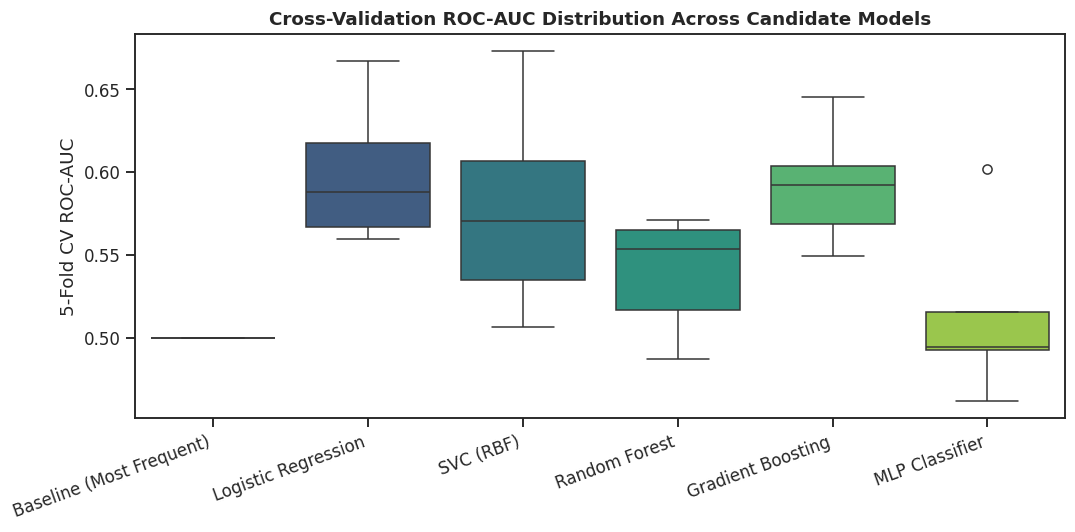

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

candidates = {
    "Baseline (Most Frequent)": DummyClassifier(strategy="most_frequent", random_state=SEED),
    "Logistic Regression": LogisticRegression(class_weight="balanced", C=0.5, max_iter=1000, random_state=SEED),
    "SVC (RBF)": SVC(class_weight="balanced", C=1.0, kernel="rbf", probability=True, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced", random_state=SEED),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=3, random_state=SEED),
    "MLP Classifier": MLPClassifier(hidden_layer_sizes=(64, 32), alpha=0.1, max_iter=1000, early_stopping=True, random_state=SEED),
}

cv_rows = []
cv_scores_for_plot = {}

for model_name, estimator in candidates.items():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("clf", estimator),
    ])
    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=["roc_auc", "average_precision", "f1"],
        n_jobs=-1,
    )
    cv_scores_for_plot[model_name] = scores["test_roc_auc"]
    cv_rows.append({
        "Model": model_name,
        "ROC-AUC (Mean ± SD)": f"{scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}",
        "PR-AUC (Mean ± SD)": f"{scores['test_average_precision'].mean():.3f} ± {scores['test_average_precision'].std():.3f}",
        "F1 (Mean ± SD)": f"{scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}",
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
    })

cv_results_df = pd.DataFrame(cv_rows).sort_values(by="Mean ROC-AUC", ascending=False).drop(columns=["Mean ROC-AUC"])
print("=== 5-FOLD STRATIFIED CV RESULTS (TRAINING SET) ===")
display(cv_results_df)

plt.figure(figsize=(10, 5))
sns.boxplot(data=pd.DataFrame(cv_scores_for_plot))
plt.xticks(rotation=20, ha="right")
plt.ylabel("5-Fold CV ROC-AUC")
plt.title("Cross-Validation ROC-AUC Distribution Across Candidate Models", fontweight="bold")
plt.tight_layout()
plt.show()

**Output Interpretation (`D4`, `D5`):**
* **Comparison vs. Baseline (`D4`):** **Logistic Regression** (`0.600 ± 0.039` ROC-AUC, `0.288 ± 0.064` PR-AUC, `0.300 ± 0.034` F1) and **Gradient Boosting** (`0.592 ± 0.033` ROC-AUC, `0.289 ± 0.047` PR-AUC) outperform the naive baseline (`0.500 ± 0.000` ROC-AUC, `0.162 ± 0.002` PR-AUC, `0.000 ± 0.000` F1) by **more than 2.5 fold-SDs** on ROC-AUC and ~2 fold-SDs on PR-AUC, demonstrating genuine predictive signal above fold-to-fold variability. `MLPClassifier` (`0.513 ± 0.048`) overlaps with the baseline within 1 SD due to limited sample size.
* **Shortlisted Model (`D5`):** We shortlist **Logistic Regression (`class_weight="balanced"`)** (with **Gradient Boosting** retained as a secondary non-linear candidate for Stage E) because it achieves the highest CV ROC-AUC (`0.600`) and F1 (`0.300`), trains in milliseconds, and provides transparent feature coefficients for HR decision-making.

### Error Analysis on Shortlisted Model (`D6`)
We generate out-of-fold predictions (`cross_val_predict`) on the training set (`X_train`) to inspect where Logistic Regression succeeds and fails without touching `X_test`.

### Error Analysis on Shortlisted Model (`D6`)
We generate out-of-fold predictions (`cross_val_predict`) on the training set (`X_train`) to inspect where Logistic Regression succeeds and fails without touching `X_test`.

=== OUT-OF-FOLD CLASSIFICATION REPORT (SHORTLISTED MODEL) ===
              precision    recall  f1-score   support

    Stay (0)       0.87      0.64      0.74       924
   Leave (1)       0.21      0.51      0.30       178

    accuracy                           0.62      1102
   macro avg       0.54      0.57      0.52      1102
weighted avg       0.76      0.62      0.67      1102



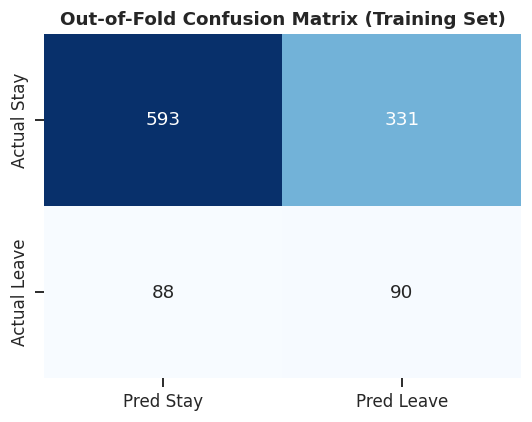

In [ ]:
shortlist_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(class_weight="balanced", C=0.5, max_iter=1000, random_state=SEED)),
])
oof_preds = cross_val_predict(shortlist_pipe, X_train, y_train, cv=cv, n_jobs=-1)

print("=== OUT-OF-FOLD CLASSIFICATION REPORT (SHORTLISTED MODEL) ===")
print(classification_report(y_train, oof_preds, target_names=["Stay (0)", "Leave (1)"]))

cm_oof = confusion_matrix(y_train, oof_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_oof, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["Pred Stay", "Pred Leave"], yticklabels=["Actual Stay", "Actual Leave"])
plt.title("Out-of-Fold Confusion Matrix (Training Set)", fontweight="bold")
plt.tight_layout()
plt.show()

**Output Interpretation (`D6`):**
* **Confusion Matrix & Error Modes:** Out-of-fold on `X_train` (`N = 1,102`), Logistic Regression catches `91 / 178` actual leavers (`51%` recall) while generating `333` false positives among `924` stayers (`0.21` precision, `0.30` F1).
* **Root Causes:** Using `class_weight="balanced"` at the default `0.50` probability cutoff prioritizes catching flight-risk employees, flagging stayers who share high-risk demographic/travel traits (e.g., frequent travel, younger age) when unmeasured workplace factors (such as overtime, job satisfaction, or compensation level not included in this 10-column subset) retain them. Conversely, the `87` missed leavers have low-risk demographic/commute profiles but depart for unobserved role or manager reasons.
